# Social Media & Mental Health — Classification Mini Project

**Group 4:**  Jana , Leen , Abdulrahman , Ahmed

**Dataset:** [Social Media and Mental Health](https://www.kaggle.com/datasets/souvikahmed071/social-media-and-mental-health) (Kaggle, `smmh.csv`) — 481 survey responses, 21 columns

**Algorithms:** Logistic Regression & K-Nearest Neighbors

# **1. Introduction**

Social media has become an important part of people's daily lives, and its use may be associated with changes in mental health and daily behavior. In this project, we use the Social Media and Mental Health dataset to classify participants based on their reported mental health signs.

The dataset includes information about participants' demographics, social media usage, and behavioral patterns. The raw data has **no label column**, so the target variable is created by combining the answers to the mental-health questions into one mental-health score, which is then used to classify participants into two groups: `needs_help = 0` (lower symptom burden) and `needs_help = 1` (higher symptom burden). The exact definition is given in the EDA section.

Our assigned algorithms are K-Nearest Neighbors (KNN) Classification and Logistic Regression.

We explain how they work, explore the data, prepare it for modeling, train and tune both models, evaluate their performance using Accuracy, Precision, Recall, F1-score and the confusion matrix, and finally compare the two models.

# **2. Algorithms Explanation**

## **1. K-Nearest Neighbors (KNN) Classification**

### **A. What is the algorithm?**

K-Nearest Neighbors (KNN) Classification is a supervised machine learning algorithm used to predict the class of a new data point based on the classes of its most similar examples in the training data.

It is a non-parametric, instance-based (lazy) learner. This means it does not learn a fixed equation during training. Instead, it stores the training data and uses it directly when making predictions.

Example: We want to predict whether a new participant belongs to the needs_help = 0 or needs_help = 1 class based on their behavioral responses.

Suppose the participant has the following responses to three behavioral questions:

| Feature | Response |
|---|---|
| Q9 | 4 |
| Q10 | 5 |
| Q11 | 4 |



With K = 3, KNN searches the training data and finds the 3 most similar participants based on their feature values.

For example:

| Neighbor | Q9 | Q10 | Q11 | Class |
|---|---|---|---|---|
| 1 | 4 | 5 | 3 | needs_help = 1 |
| 2 | 5 | 4 | 4 | needs_help = 1 |
| 3 | 3 | 5 | 4 | needs_help = 0 |

The model checks the class of each neighbor:

needs_help = 1: 2 participants

needs_help = 0: 1 participant

The majority class is needs_help = 1.

Therefore, KNN predicts that the new participant belongs to the needs_help = 1 class.

The class labels in the training data were previously determined using the mental-health score created from the six symptom questions (Q12, Q13, Q14, Q18, Q19, Q20).

### **B. How does the algorithm work?**



*   **Store the data :** The model keeps the training examples and their known class labels.

*   **Measure similarity :** When a new participant is given, the model calculates the distance between their behavioral responses and those of the participants in the training data.


*   **Find the nearest neighbors:** It selects the K participants with the smallest distances.
*   
**Vote for a class:** The model checks which class appears most often among those neighbors.




*   **Make a prediction:** The new participant is assigned to the majority class. Closer neighbors can also be given more weight when using distance weighting.




**Choosing K:**

*   **K too small :** The prediction depends on only one neighbor, so noise
or an unusual example can affect the result. This may lead to overfitting.

*   **K too large:** The model considers too many neighbors, including participants who may not be very similar. This can make predictions too general and lead to underfitting.

We try different values of K and select the one that gives the best results.



### **C. When should this algorithm be used?**


*   The dataset is small to medium-sized, since predictions can become slow on large datasets.

*   There are a reasonable number of relevant features.

*  similar participants are expected to have similar class labels.

*  The relationship between features and classes may be non-linear.


* You want a simple classification method that does not require assuming a specific mathematical relationship between the features and target.







### **D. Advantages and Limitations**

Advantages:


*   Simple and easy to understand.

*   No complex training process; the model stores the training data


*   Can capture non-linear relationships.

*   Makes no assumptions about the shape of the decision boundary.

*   Can use different distance measures and weighting methods.




Limitations


*   Needs feature scaling because features with larger values can dominate the distance calculation.
*   
Predictions can be slow on large datasets


*   Performance can decrease when there are many irrelevant features.
*   Sensitive to noise, especially when K is small


*   Choosing the right value of K is important.

*   Can struggle when classes are imbalanced or when the data has many dimensions.
















## **2. Logistic Regression**

### **A. What is the algorithm?**

Logistic Regression is a supervised machine learning algorithm used for classification. It predicts the probability that a participant belongs to a particular class.

In our project, Logistic Regression is used to classify participants into two groups: needs_help = 0 and needs_help = 1.

For example, if the model predicts a probability of 0.80, this means it estimates an 80% probability that the participant belongs to the needs_help = 1 class. Using a threshold of 0.5, the participant would be classified as needs_help = 1.

### **B. How does the algorithm work?**

**Input the features:** The model receives the selected features for each participant.

**Calculate a weighted sum**: It multiplies each feature by a learned coefficient and combines the results with an intercept.

**Apply the Sigmoid function:** The result is passed through the Sigmoid function, which converts it into a probability between 0 and 1.

**Compare with a threshold**: The predicted probability is compared with a threshold, commonly 0.5.

**Make a prediction:**

**Probability ≥ 0.5:** Class 1 (needs_help = 1).

**Probability < 0.5:** Class 0 (needs_help = 0).

The model learns its coefficients during training by adjusting them to reduce the classification error.

### **C. When should this algorithm be used?**



*   The target variable has two classes, such as needs_help = 0 and needs_help = 1.
*   You want to estimate the probability of belonging to a class.



*   The relationship between the features and the log-odds of the target can be reasonably represented as linear.
*   You want a model that is relatively simple and easy to interpret.



*   You want to understand how features are associated with the predicted class through the model coefficients.



### **D. Advantages and Limitations**

**Advantages**




*   Simple and relatively fast to train.
*   Designed for classification problems.


*   Provides probabilities for class predictions.
*   Coefficients help explain how features are associated with the target.



*   Works well when the relationship between the features and the log-odds is approximately linear.












**Limitations**

*   Assumes a linear relationship between the features and the log-odds of the target.
*   May not perform well with complex non-linear relationships.


*   Can be affected by highly correlated features.
*   May require feature scaling depending on the data and regularization used.

*   Its performance can be affected by class imbalance.
*   The default 0.5 classification threshold may not always be the most suitable choice.

# **3. Data Exploration**

In [1]:
# Data handling
import pandas as pd
import numpy as np

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# Dataset download
import kagglehub
import os

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Plot styling
BLUE, ORANGE, AQUA, YELLOW, MAGENTA = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"
CAT = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False,
                                     "grid.color": "#e6e6e3", "figure.dpi": 110})

In [2]:
path = kagglehub.dataset_download("souvikahmed071/social-media-and-mental-health")
print("Downloaded to:", path)
print(os.listdir(path))

df = pd.read_csv(os.path.join(path, "smmh.csv"))
print(df.shape)
df.head()

Using Colab cache for faster access to the 'social-media-and-mental-health' dataset.
Downloaded to: /kaggle/input/social-media-and-mental-health
['smmh.csv']
(481, 21)


,Timestamp,1. What is your age?,2. Gender,3. Relationship Status,4. Occupation Status,5. What type of organizations are you affiliated with?,6. Do you use social media?,7. What social media platforms do you commonly use?,8. What is the average time you spend on social media every day?,9. How often do you find yourself using Social media without a specific purpose?,...,11. Do you feel restless if you haven't used Social media in a while?,"12. On a scale of 1 to 5, how easily distracted are you?","13. On a scale of 1 to 5, how much are you bothered by worries?",14. Do you find it difficult to concentrate on things?,"15. On a scale of 1-5, how often do you compare yourself to other successful people through the use of social media?","16. Following the previous question, how do you feel about these comparisons, generally speaking?",17. How often do you look to seek validation from features of social media?,18. How often do you feel depressed or down?,"19. On a scale of 1 to 5, how frequently does your interest in daily activities fluctuate?","20. On a scale of 1 to 5, how often do you face issues regarding sleep?"
0,4/18/2022 19:18:47,21.0,Male,In a relationship,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",Between 2 and 3 hours,5,...,2,5,2,5,2,3,2,5,4,5
1,4/18/2022 19:19:28,21.0,Female,Single,University Student,University,Yes,"Facebook, Twitter, Instagram, YouTube, Discord...",More than 5 hours,4,...,2,4,5,4,5,1,1,5,4,5
2,4/18/2022 19:25:59,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube, Pinterest",Between 3 and 4 hours,3,...,1,2,5,4,3,3,1,4,2,5
3,4/18/2022 19:29:43,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram",More than 5 hours,4,...,1,3,5,3,5,1,2,4,3,2
4,4/18/2022 19:33:31,21.0,Female,Single,University Student,University,Yes,"Facebook, Instagram, YouTube",Between 2 and 3 hours,3,...,4,4,5,5,3,3,3,4,4,1


### 1. Dataset structure

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 481 entries, 0 to 480
Data columns (total 21 columns):
 #   Column                                                                                                                Non-Null Count  Dtype  
---  ------                                                                                                                --------------  -----  
 0   Timestamp                                                                                                             481 non-null    object 
 1   1. What is your age?                                                                                                  481 non-null    float64
 2   2. Gender                                                                                                             481 non-null    object 
 3   3. Relationship Status                                                                                                481 non-null    object 
 4   4. Occup

The column names are full survey questions, which is painful to work with. We rename them to short snake_case names (and keep a dictionary so the meaning is never lost).

In [4]:
rename = {
    "Timestamp": "timestamp",
    "1. What is your age?": "age",
    "2. Gender": "gender",
    "3. Relationship Status": "relationship",
    "4. Occupation Status": "occupation",
    "5. What type of organizations are you affiliated with?": "organizations",
    "6. Do you use social media?": "uses_sm",
    "7. What social media platforms do you commonly use?": "platforms",
    "8. What is the average time you spend on social media every day?": "daily_time",
    "9. How often do you find yourself using Social media without a specific purpose?": "purposeless_use",
    "10. How often do you get distracted by Social media when you are busy doing something?": "distracted_by_sm",
    "11. Do you feel restless if you haven't used Social media in a while?": "restless",
    "15. On a scale of 1-5, how often do you compare yourself to other successful people through the use of social media?": "comparison",
    "16. Following the previous question, how do you feel about these comparisons, generally speaking?": "comparison_feeling",
    "17. How often do you look to seek validation from features of social media?": "validation",
    "12. On a scale of 1 to 5, how easily distracted are you?": "easily_distracted",
    "13. On a scale of 1 to 5, how much are you bothered by worries?": "worries",
    "14. Do you find it difficult to concentrate on things?": "concentration",
    "18. How often do you feel depressed or down?": "depressed",
    "19. On a scale of 1 to 5, how frequently does your interest in daily activities fluctuate?": "interest_fluctuation",
    "20. On a scale of 1 to 5, how often do you face issues regarding sleep?": "sleep_issues",
}
df = df.rename(columns=rename)

SM_USAGE_Q = ["purposeless_use", "distracted_by_sm", "restless", "comparison", "comparison_feeling", "validation"]
MENTAL_Q   = ["easily_distracted", "worries", "concentration", "depressed", "interest_fluctuation", "sleep_issues"]
LIKERT_Q   = SM_USAGE_Q + MENTAL_Q

df.columns.tolist()

['timestamp',
 'age',
 'gender',
 'relationship',
 'occupation',
 'organizations',
 'uses_sm',
 'platforms',
 'daily_time',
 'purposeless_use',
 'distracted_by_sm',
 'restless',
 'easily_distracted',
 'worries',
 'concentration',
 'comparison',
 'comparison_feeling',
 'validation',
 'depressed',
 'interest_fluctuation',
 'sleep_issues']

In [5]:
# Keep a lookup table so the original question is never lost
column_dictionary = pd.DataFrame({"short_name": list(rename.values()),
                                  "original_question": list(rename.keys())})
column_dictionary

,short_name,original_question
0,timestamp,Timestamp
1,age,1. What is your age?
2,gender,2. Gender
3,relationship,3. Relationship Status
4,occupation,4. Occupation Status
5,organizations,5. What type of organizations are you affiliat...
6,uses_sm,6. Do you use social media?
7,platforms,7. What social media platforms do you commonly...
8,daily_time,8. What is the average time you spend on socia...
9,purposeless_use,9. How often do you find yourself using Social...


**Observation – dataset structure**

- **21 columns** in total:
  - 1 timestamp (`timestamp`)
  - 1 numeric column (`age`)
  - 6 categorical / text columns (`gender`, `relationship`, `occupation`, `organizations`, `uses_sm`, `platforms`, `daily_time`)
  - 12 Likert-scale questions, each scored 1–5
- The 12 Likert questions split naturally into two groups:
  - **Social-media behaviour (6):** `purposeless_use`, `distracted_by_sm`, `restless`, `comparison`, `comparison_feeling`, `validation`
  - **Mental-health symptoms (6):** `easily_distracted`, `worries`, `concentration`, `depressed`, `interest_fluctuation`, `sleep_issues`
- This split is the key to the project: the **symptom questions will be used to build the target**, and the **behaviour questions + demographics will be the features**.

### 2. Missing values and duplicates

In [6]:
missing = df.isna().sum()
missing[missing > 0]

,0
organizations,30


In [7]:
print(f"Only 'organizations' has missing values: {df['organizations'].isna().sum()} of {len(df)} rows ({df['organizations'].isna().mean():.1%}).")

Only 'organizations' has missing values: 30 of 481 rows (6.2%).


In [8]:
df['organizations'].value_counts()

,count
organizations,
University,239
Private,60
School,44
Company,30
"University, Company",19
"University, Private",16
"School, University",9
"Company, Private",7
Goverment,6


In [9]:
# Handle the missing values right away
df["organizations"] = df["organizations"].fillna("Unknown")

# fix the spelling mistake and the "N/A" answers while we are here
df["organizations"] = (df["organizations"]
                       .str.replace("Goverment", "Government")
                       .str.replace(", N/A", ""))

print("Missing values left:", df.isna().sum().sum())
df["organizations"].value_counts()

Missing values left: 0


,count
organizations,
University,242
Private,60
School,46
Company,30
Unknown,30
"University, Company",19
"University, Private",16
"School, University",9
"Company, Private",7


In [10]:
# check for duplicated rows
print("Duplicated rows:", df.duplicated().sum())

Duplicated rows: 0


**Observation – missing values and duplicates**

- The dataset is almost complete: out of 21 columns, only `organizations` has missing values (30 rows, about 6%).
- There are no duplicated rows, so every row is a different respondent.
- All the Likert questions, `age`, `gender`, `daily_time`, etc. have no missing values, so we do not need to delete any rows.
- Looking at `organizations` more closely, the answers are free text and multi-select, and some of them are inconsistent (for example `"University, N/A"`, or `"Goverment"` with a spelling mistake).
- For now we keep the column as it is. We will decide how to handle it (fill the missing values or drop it) after checking whether it has any relationship with the target.
- **We do not remove outliers.** The Likert questions only take values 1–5, so an answer of 1 or 5 is a normal response and not an outlier; removing such rows would delete exactly the clearest high-sign and low-sign cases. The only wide-range column is `age`, which we examine below.

### 3. Descriptive statistics

In [11]:
df[["age"] + LIKERT_Q].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,481.0,26.14,9.92,13.0,21.0,22.0,26.0,91.0
purposeless_use,481.0,3.55,1.10,1.0,3.0,4.0,4.0,5.0
distracted_by_sm,481.0,3.32,1.33,1.0,2.0,3.0,4.0,5.0
restless,481.0,2.59,1.26,1.0,2.0,2.0,3.0,5.0
comparison,481.0,2.83,1.41,1.0,2.0,3.0,4.0,5.0
comparison_feeling,481.0,2.78,1.06,1.0,2.0,3.0,3.0,5.0
validation,481.0,2.46,1.25,1.0,1.0,2.0,3.0,5.0
easily_distracted,481.0,3.35,1.18,1.0,3.0,3.0,4.0,5.0
worries,481.0,3.56,1.28,1.0,3.0,4.0,5.0,5.0
concentration,481.0,3.25,1.35,1.0,2.0,3.0,4.0,5.0


**Observations**

- **Age:** the median age is around 22 but the mean is around 26, and the oldest respondent is 91. Since the mean is higher than the median, we can tell that most people in the survey are young and a few older respondents are pulling the average up.
- **Likert questions:** all 12 questions have a minimum of 1 and a maximum of 5, so the full scale was used and there are no strange or out-of-range values.
- The two questions with the highest means are `worries` (3.56) and `purposeless_use` (3.55). This means a lot of respondents say they worry often and open social media without a specific reason.
- The question with the lowest mean is `validation` (2.46), so looking for validation from likes and comments is not very common in our sample.

# **4. Exploratory Data Analysis (EDA)**

### **4.1 Univariate analysis**

#### 4.1.1 Who answered the survey?

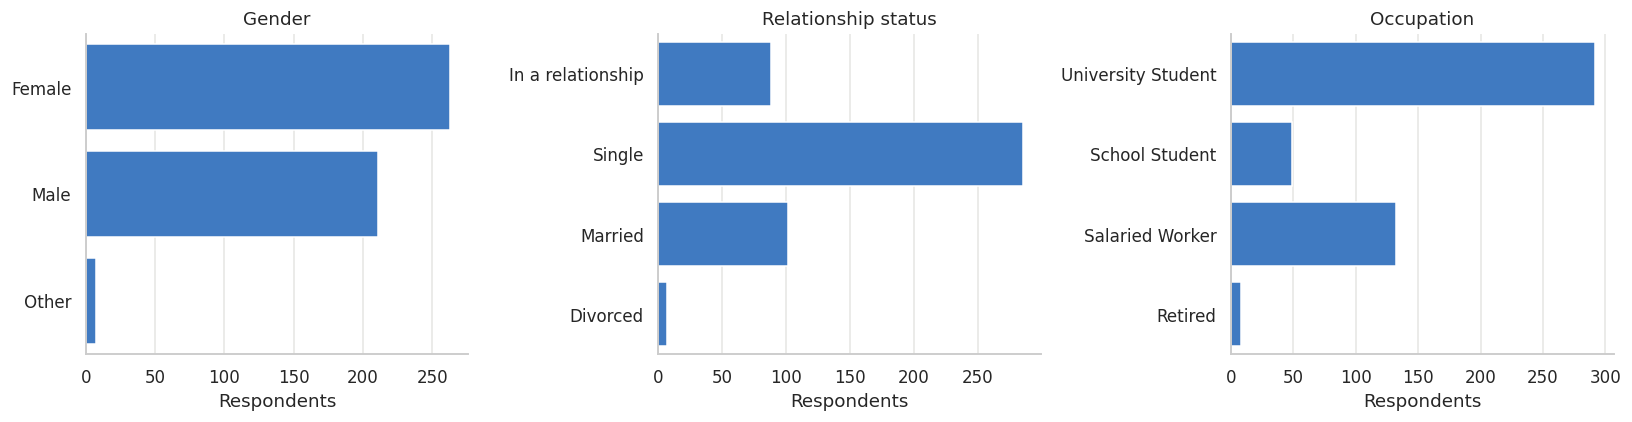

In [12]:
# Group the 7 free-text gender answers into "Other" (for the chart only)
gender_counts = df["gender"].value_counts()
gender_counts = gender_counts[gender_counts > 1]
gender_counts["Other"] = len(df) - gender_counts.sum()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Gender
sns.barplot(x=gender_counts.values, y=gender_counts.index, color=BLUE, ax=axes[0])
axes[0].set_title("Gender")

# Relationship status
sns.countplot(data=df, y="relationship", color=BLUE, ax=axes[1])
axes[1].set_title("Relationship status")

# Occupation
sns.countplot(data=df, y="occupation", color=BLUE, ax=axes[2])
axes[2].set_title("Occupation")

for ax in axes:
    ax.set_xlabel("Respondents")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()

**Observations**

- Gender is fairly balanced: 263 female and 211 male respondents.
- The remaining 7 people typed their own answer (`Nonbinary`, `Non-binary`, `NB`, `Non binary`, `Trans`, `unsure`, `There are others???`). Several of these mean the same thing but are spelled differently, so if we one-hot encode the column as it is we would get 7 extra columns with one person each. In preprocessing we should group them into a single `Other` category.
- Most respondents are university students (61%) and single (59%), so the sample mainly represents young adults. We should mention this as a limitation, because the results may not generalise well to older people or workers.

#### 4.1.2 Age distribution

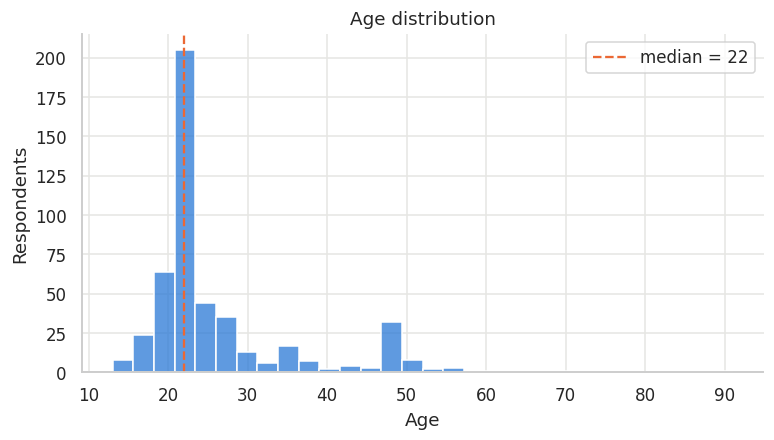

In [13]:
plt.figure(figsize=(8, 4))
sns.histplot(df["age"], bins=30, color=BLUE)

# dashed line at the median age
median_age = df["age"].median()
plt.axvline(median_age, color=ORANGE, linestyle="--", label=f"median = {median_age:.0f}")

plt.title("Age distribution")
plt.xlabel("Age")
plt.ylabel("Respondents")
plt.legend()
plt.show()

In [14]:
print("Respondents older than 60:", (df.age > 60).sum())
df.loc[df.age > 60, ["age", "occupation", "daily_time"]]

Respondents older than 60: 3


,age,occupation,daily_time
46,65.0,Retired,Between 3 and 4 hours
238,69.0,Salaried Worker,More than 5 hours
256,91.0,University Student,Between 2 and 3 hours


**Observation**

- The histogram shows right-skewed distribution: most respondents are between 18 and 30, and then there is a long tail towards older ages.
- There are only 3 respondents older than 60. When we check their rows they are retired people with normal answers, so these look like real values and not typing mistakes, and we decided to keep them.
- These older ages are still outliers compared to the rest of the sample. KNN uses distances between points, so a feature with such a wide range can dominate the distance calculation. Because of this, `age` has to be scaled before training, and it may also be worth trying a log transform to reduce the skew and see if it improves the models.

#### 4.1.3 Daily time on social media

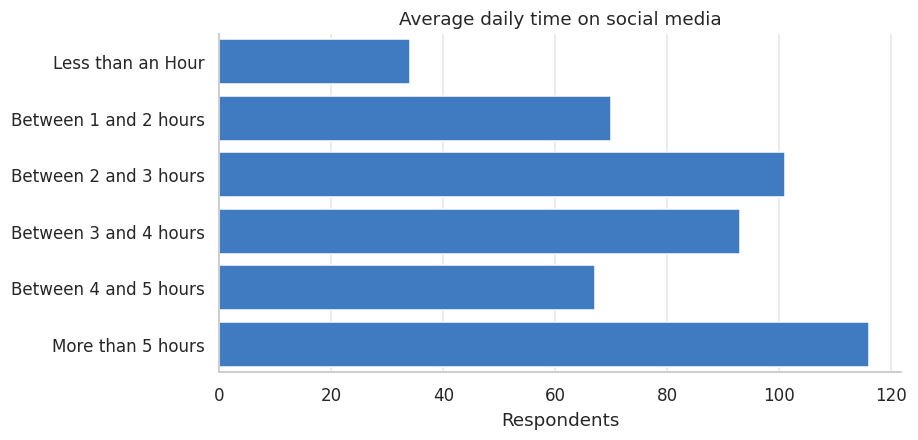

24% of respondents spend more than 5 hours a day on social media.


In [15]:
# order the categories from least to most time
time_order = ["Less than an Hour", "Between 1 and 2 hours", "Between 2 and 3 hours",
              "Between 3 and 4 hours", "Between 4 and 5 hours", "More than 5 hours"]

plt.figure(figsize=(8, 4))
sns.countplot(data=df, y="daily_time", order=time_order, color=BLUE)
plt.title("Average daily time on social media")
plt.xlabel("Respondents")
plt.ylabel("")
plt.show()

# share of heavy users
heavy = (df["daily_time"] == "More than 5 hours").mean()
print(f"{heavy:.0%} of respondents spend more than 5 hours a day on social media.")

**Observations**
- The most common answer is **“More than 5 hours” (24%)**; only 7% use social media under an hour a day. This is a heavy-use sample.
- `uses_sm` is "Yes" for 478/481 rows, it carries no information and should be **dropped**.

#### 4.1.4 Platforms used

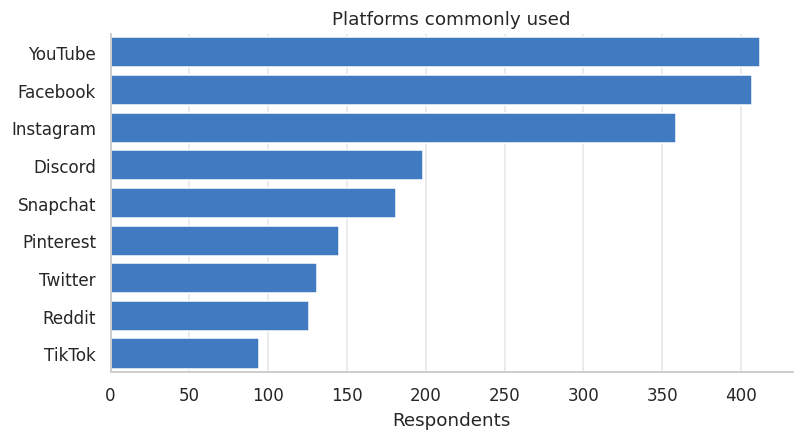

Average number of platforms per person: 4.27


In [16]:
# split the comma-separated answers into one 0/1 column per platform
platforms = df["platforms"].str.get_dummies(sep=", ")

# how many people use each platform
counts = platforms.sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4))
sns.barplot(x=counts.values, y=counts.index, color=BLUE)
plt.title("Platforms commonly used")
plt.xlabel("Respondents")
plt.ylabel("")
plt.show()

# new feature: number of platforms each person uses
df["n_platforms"] = platforms.sum(axis=1)
print("Average number of platforms per person:", round(df["n_platforms"].mean(), 2))

**Observation**

- Facebook, YouTube and Instagram are the most used platforms; almost everyone in the sample uses Facebook.
- Respondents use about 4 platforms on average, so we created a new feature `n_platforms` (number of platforms per person).
- The original `platforms` column is a comma-separated text with many different combinations, so in preprocessing it should be split into one 0/1 column per platform instead of being one-hot encoded as a whole string.

#### 4.1.5 Gender across relationship status

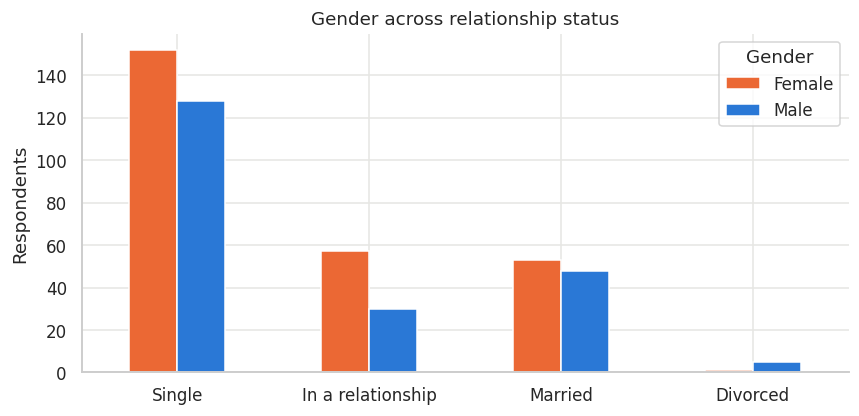

gender,Female,Male
relationship,,
Single,152,128
In a relationship,57,30
Married,53,48
Divorced,1,5


In [17]:
# Gender distribution across relationship status (Male / Female only, the 7 "Other" answers are too few to plot)
gender_df = df[df["gender"].isin(["Male", "Female"])]
relationship_order = ["Single", "In a relationship", "Married", "Divorced"]

relationship_gender = pd.crosstab(gender_df["relationship"], gender_df["gender"]).reindex(relationship_order)
relationship_gender.plot(kind="bar", figsize=(9, 4), color=[ORANGE, BLUE])
plt.title("Gender across relationship status")
plt.xlabel("")
plt.ylabel("Respondents")
plt.xticks(rotation=0)
plt.legend(title="Gender")
plt.show()

relationship_gender

**Observation**

- Single respondents are the largest group for both genders, and the female/male ratio is similar across the four groups.
- Because the split looks similar everywhere, `gender` and `relationship` are not strongly linked to each other, so they can both be used as separate features without carrying the same information twice.

### **4.2 Defining the target variable**

The raw dataset has **no label**, so we build one from the six mental-health symptom questions:

| Question | Column |
|---|---|
| Q12 How easily distracted are you? | `easily_distracted` |
| Q13 How much are you bothered by worries? | `worries` |
| Q14 Do you find it difficult to concentrate? | `concentration` |
| Q18 How often do you feel depressed or down? | `depressed` |
| Q19 How frequently does your interest in daily activities fluctuate? | `interest_fluctuation` |
| Q20 How often do you face issues regarding sleep? | `sleep_issues` |

1. **`mh_score`** = sum of the six answers → ranges from **6** (no symptoms) to **30** (all symptoms very often).
2. **`needs_help`** = binary label: `1` if `mh_score` is above the median, otherwise `0`.

The remaining questions (social-media behaviour Q9–11, Q15–17) and the demographics stay available as **features**, so the models answer the dataset's original question: *do social-media habits predict a higher mental-health symptom burden?*

> These are self-reported indicators, not a clinical diagnosis, and the median split is a modelling choice.

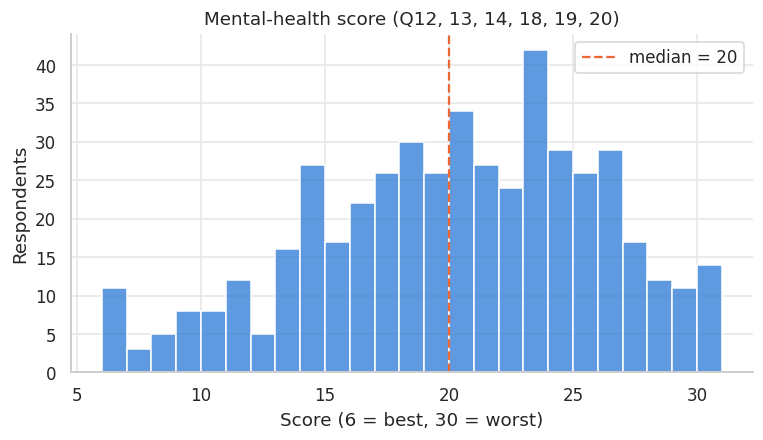

needs_help
0    250
1    231
Name: count, dtype: int64
needs_help
0    0.52
1    0.48
Name: proportion, dtype: float64


In [18]:
# mental-health score = sum of the 6 symptom questions (range 6–30)
df["mh_score"] = df[MENTAL_Q].sum(axis=1)

# target: 1 if the score is above the median, otherwise 0
threshold = df["mh_score"].median()
df["needs_help"] = (df["mh_score"] > threshold).astype(int)

plt.figure(figsize=(8, 4))
sns.histplot(df["mh_score"], bins=range(6, 32), color=BLUE)
plt.axvline(threshold, color=ORANGE, linestyle="--", label=f"median = {threshold:.0f}")
plt.title("Mental-health score (Q12, 13, 14, 18, 19, 20)")
plt.xlabel("Score (6 = best, 30 = worst)")
plt.ylabel("Respondents")
plt.legend()
plt.show()

print(df["needs_help"].value_counts())
print(df["needs_help"].value_counts(normalize=True).round(2))

**Observation – target variable**

- The score looks roughly bell-shaped, with most respondents between 17 and 23 and the peak around 19–20.
- Splitting at the median (20) gives 250 respondents in class 0 and 231 in class 1 (about 52% / 48%), so the classes are almost balanced and accuracy is a fair metric.
- We will still report precision, recall, F1 and the confusion matrix as required by the project.

### **4.3 Bivariate analysis** (what relates to the target?)

#### 4.3.1 Correlation heatmap

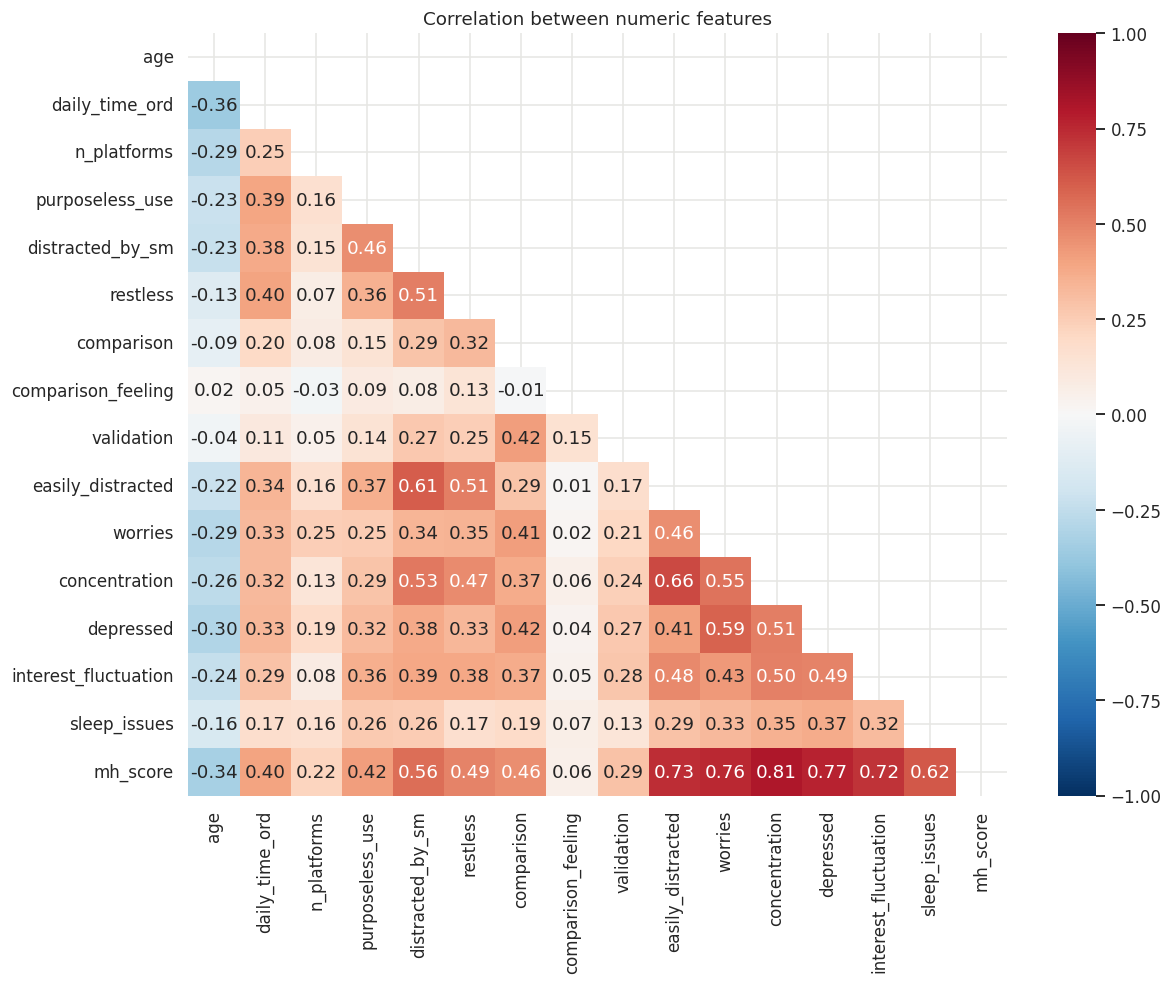

In [19]:
# convert daily_time to numbers 0–5 so it can go into the correlation
time_map = {"Less than an Hour": 0, "Between 1 and 2 hours": 1, "Between 2 and 3 hours": 2,
            "Between 3 and 4 hours": 3, "Between 4 and 5 hours": 4, "More than 5 hours": 5}
df["daily_time_ord"] = df["daily_time"].map(time_map)

# numeric columns to include
num_cols = ["age", "daily_time_ord", "n_platforms"] + LIKERT_Q + ["mh_score"]
corr = df[num_cols].corr()

# mask hides the upper triangle (it is a mirror of the lower one)
mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(12, 9))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation between numeric features")
plt.show()

In [20]:
print("Correlation of each candidate feature with mh_score:\n")
print(corr["mh_score"].drop(MENTAL_Q + ["mh_score"]).sort_values(ascending=False).round(3))

Correlation of each candidate feature with mh_score:

distracted_by_sm      0.561
restless              0.494
comparison            0.464
purposeless_use       0.415
daily_time_ord        0.402
validation            0.294
n_platforms           0.220
comparison_feeling    0.057
age                  -0.335
Name: mh_score, dtype: float64


**Observations – correlation heatmap**

- Five of the six social-media behaviour questions have a positive correlation with the score. The strongest ones are `distracted_by_sm` (r = 0.56), `restless` (0.49), `comparison` (0.46) and `purposeless_use` (0.42). So the more someone shows these behaviours, the higher their symptom score tends to be.
- `daily_time_ord` also correlates positively with the score (r = 0.40): people who spend more hours on social media report more symptoms. This is the main relationship the dataset was collected to study.
- `comparison_feeling` is almost not correlated with the score at all (r = 0.06), so we do not expect it to help the models much.
- `age` has a negative correlation (r = −0.34): older respondents report fewer symptoms, and they also spend less time on social media.
- Some features are correlated with each other, for example `distracted_by_sm` with `purposeless_use` and `restless` (r ≈ 0.5). This is not a problem for KNN, but we should keep it in mind when we read the Logistic Regression coefficients, because correlated features can share the same effect between them.

#### 4.3.2 Daily time vs mental-health score

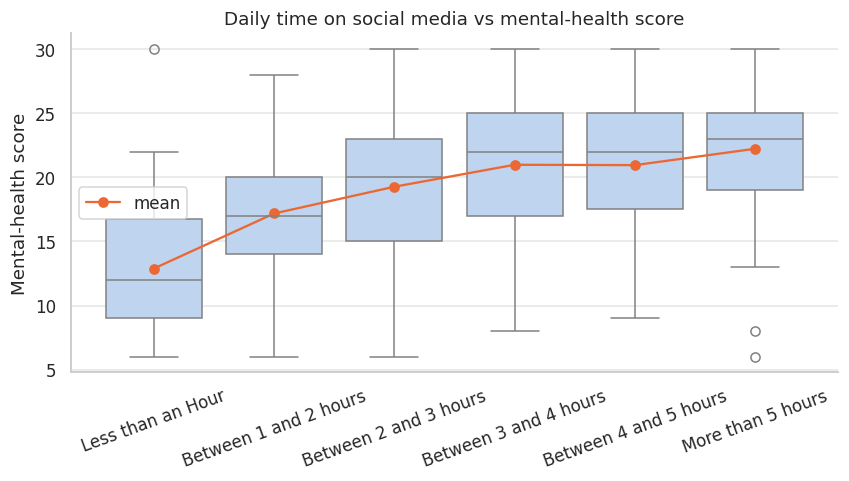

,mh_score
daily_time,
Less than an Hour,12.88
Between 1 and 2 hours,17.17
Between 2 and 3 hours,19.26
Between 3 and 4 hours,20.97
Between 4 and 5 hours,20.94
More than 5 hours,22.22


In [21]:
plt.figure(figsize=(9, 4))
sns.boxplot(data=df, x="daily_time", y="mh_score", order=time_order, color="#b7d3f6")

# average score for each time group, drawn as an orange line over the boxes
means = df.groupby("daily_time")["mh_score"].mean().reindex(time_order)
plt.plot(range(6), means.values, "o-", color=ORANGE, label="mean")

plt.title("Daily time on social media vs mental-health score")
plt.xlabel("")
plt.ylabel("Mental-health score")
plt.xticks(rotation=20)
plt.legend()
plt.show()

means.round(2)

**Observation – daily time vs mental-health score**

- There is a clear upward trend: the average score goes from 12.9 for people who use social media less than an hour a day up to 22.2 for people who use it more than 5 hours.
- The increase is almost step by step across the groups; only the 3–4 h and 4–5 h groups are about the same (around 21).
- Because the order of the categories matters here, `daily_time` should be encoded as ordinal (0 to 5) and not one-hot, and it looks like one of the most useful features for predicting the target.

#### 4.3.3 Target rate by group

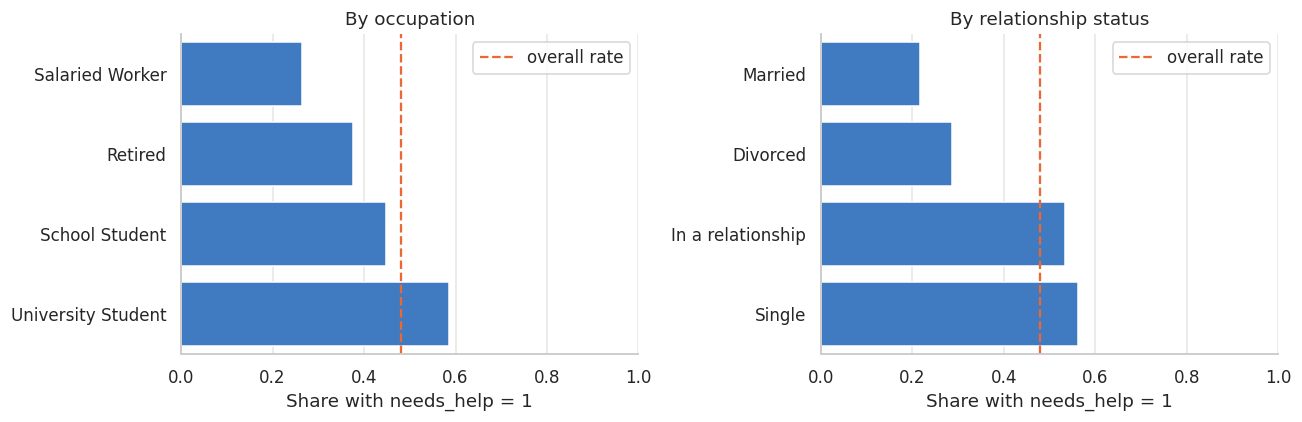

In [22]:
# share of people with needs_help = 1 inside each group
overall_rate = df["needs_help"].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# by occupation
rate_occ = df.groupby("occupation")["needs_help"].mean().sort_values()
sns.barplot(x=rate_occ.values, y=rate_occ.index, color=BLUE, ax=axes[0])
axes[0].set_title("By occupation")

# by relationship status
rate_rel = df.groupby("relationship")["needs_help"].mean().sort_values()
sns.barplot(x=rate_rel.values, y=rate_rel.index, color=BLUE, ax=axes[1])
axes[1].set_title("By relationship status")

# same formatting for both + dashed line = overall rate
for ax in axes:
    ax.axvline(overall_rate, color=ORANGE, linestyle="--", label="overall rate")
    ax.set_xlim(0, 1)
    ax.set_xlabel("Share with needs_help = 1")
    ax.set_ylabel("")
    ax.legend()

plt.tight_layout()
plt.show()

**Observations – share of "needs help" by occupation and relationship**

- University students (59%) are clearly above the overall rate of 48%, while salaried workers (27%) are well below it. This fits what we saw with age: younger respondents tend to have higher symptom scores.
- Single (56%) and in-a-relationship (53%) respondents are similar, while married respondents are much lower (22%). Married people are also older on average, so this is probably related to the age effect as well.
- Divorced (7 people) and retired (8 people) are very small groups, so their percentages should not be trusted too much.

### **4.4 EDA summary**

1. 481 responses, no duplicates, essentially no missing data (only `organizations`, 6%, filled with `"Unknown"`).
2. Sample is young (median 22), mostly students, heavy users (24% > 5 h/day).
3. Social-media time and behaviour are clearly, positively associated with mental-health symptoms; age is negatively associated.
4. **There is no label in the raw data.** We define `needs_help = 1` when the mental-health score (sum of the six symptom questions) is above the median → 250 / 231 (52% / 48%), a balanced target.
5. `comparison_feeling` showed almost no relationship with the target; the modelling team can try with and without it.

# **5. Data Preprocessing**

**Processing already done earlier in the notebook**

Some cleaning steps were done during the data exploration and EDA, because we needed them to understand the data or to build the target. They are listed here so the full pipeline is clear:

| Step | Where | What we did |
|---|---|---|
| Renamed columns | 3.1 Dataset structure | Replaced the long survey questions with short names, and grouped the 12 Likert questions into `SM_USAGE_Q` (social-media behaviour) and `MENTAL_Q` (mental-health symptoms). |
| Missing values | 3.2 Missing values | Filled the 30 missing `organizations` values with `"Unknown"`, fixed the spelling `"Goverment"` → `"Government"` and removed the `"N/A"` answers. |
| Outliers | 3.2 and 4.1.2 | No rows removed: answers of 1 or 5 are normal Likert values, and the 3 respondents above 60 are real (retired) people. All 481 rows are kept. |
| New feature `n_platforms` | 4.1.4 Platforms used | Number of platforms each person uses (counted from the `platforms` column). |
| Target | 4.2 Defining the target | `mh_score` = sum of the six `MENTAL_Q` answers (6–30); `needs_help` = 1 if `mh_score` is above the median (20), otherwise 0. |

In this section we finish preparing the data for the models: drop the useless columns, encode the categorical columns, build `X` and `y`, split the data and scale the features.

### **5.1 Drop columns that carry no information**

In [23]:
# timestamp: just the time the form was filled
# uses_sm:   "Yes" for 478 of 481 rows, almost constant
data = df.drop(columns=["timestamp", "uses_sm"])

### **5.2 Clean gender: group the 7 free-text answers into "Other"**

In [24]:
data["gender"] = data["gender"].where(data["gender"].isin(["Male", "Female"]), "Other")
data["gender"].value_counts()

,count
gender,
Female,263
Male,211
Other,7


### **5.3 Encode daily_time as ordinal (0 = less than an hour ... 5 = more than 5 hours)**

In [25]:
time_map = {"Less than an Hour": 0, "Between 1 and 2 hours": 1, "Between 2 and 3 hours": 2,
            "Between 3 and 4 hours": 3, "Between 4 and 5 hours": 4, "More than 5 hours": 5}
data["daily_time"] = data["daily_time"].map(time_map)
data = data.drop(columns=["daily_time_ord"])

### **5.4 Split the multi-select text columns into one 0/1 column per option**

In [26]:
platform_dummies = data["platforms"].str.get_dummies(sep=", ").add_prefix("platform_")
org_dummies      = data["organizations"].str.get_dummies(sep=", ").add_prefix("org_")

data = pd.concat([data.drop(columns=["platforms", "organizations"]), platform_dummies, org_dummies], axis=1)

### **5.5 One-hot encode the remaining categorical columns**

In [27]:
data = pd.get_dummies(data, columns=["gender", "relationship", "occupation"], drop_first=True, dtype=int)
print("Shape after encoding:", data.shape)

Shape after encoding: (481, 40)


### **5.6 Build X and y**

In [28]:
# IMPORTANT (leakage): the six questions that built the target, and the score / label themselves, must not be in X
leakage_cols = MENTAL_Q + ["mh_score", "needs_help"]

X = data.drop(columns=leakage_cols)
y = data["needs_help"]

print("Features used:", X.shape[1])
print(list(X.columns))

Features used: 32
['age', 'daily_time', 'purposeless_use', 'distracted_by_sm', 'restless', 'comparison', 'comparison_feeling', 'validation', 'n_platforms', 'platform_Discord', 'platform_Facebook', 'platform_Instagram', 'platform_Pinterest', 'platform_Reddit', 'platform_Snapchat', 'platform_TikTok', 'platform_Twitter', 'platform_YouTube', 'org_Company', 'org_Government', 'org_Private', 'org_School', 'org_University', 'org_Unknown', 'gender_Male', 'gender_Other', 'relationship_In a relationship', 'relationship_Married', 'relationship_Single', 'occupation_Salaried Worker', 'occupation_School Student', 'occupation_University Student']


### **5.7 Train / test split (stratified so both sets keep the same class ratio)**

In [29]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print(y_train.value_counts(normalize=True).round(2))

Train: (384, 32)  Test: (97, 32)
needs_help
0    0.52
1    0.48
Name: proportion, dtype: float64


### **5.8 Feature scaling**

In [30]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=X.columns, index=X_test.index)

X_train_scaled.describe().T[["mean", "std"]].round(2).head()

,mean,std
age,-0.0,1.0
daily_time,-0.0,1.0
purposeless_use,0.0,1.0
distracted_by_sm,0.0,1.0
restless,-0.0,1.0


**Preprocessing summary**

- Dropped `timestamp` and `uses_sm` (no information).
- Filled the 30 missing `organizations` values with `"Unknown"`, fixed the spelling, and split it into 0/1 columns.
- Grouped the 7 free-text gender answers into `Other`, then one-hot encoded `gender`, `relationship` and `occupation`.
- Encoded `daily_time` as an ordinal 0–5 column, and split `platforms` into one column per platform plus `n_platforms`.
- Kept all 481 rows (no outlier removal, because 1–5 answers are not outliers and the old ages are real).
- Removed the six target questions and `mh_score` from `X` to avoid data leakage; `y = needs_help`.
- Stratified 80/20 split, then `StandardScaler` fitted on the training set only.

The modelling section uses `X_train_scaled`, `X_test_scaled`, `y_train` and `y_test` directly.

**Notes for the modelling team**

- Use the scaled matrices for both models.
- Expect moderate accuracy (roughly 70–80%). If you see ~99%, a target question leaked into `X`.
- `comparison_feeling` had almost no relationship with the target; try the models with and without it.
- `distracted_by_sm`, `purposeless_use` and `restless` are correlated with each other; fine for KNN, keep it in mind when interpreting the Logistic Regression coefficients.

### **6. Model Training and Tuning**

We train and optimize both **Logistic Regression** and **K-Nearest Neighbors (KNN)** using the scaled features. Following the preprocessing notes, we can also test if dropping `comparison_feeling` (which showed a correlation of only ~0.06 with the mental health score) improves generalisation.

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV

# Let's define hyperparameter grids for both models

# 1. Logistic Regression Grid
log_reg_grid = {
    'C': [0.01, 0.1, 1, 10, 100],
    'penalty': ['l2'],
    'solver': ['liblinear', 'lbfgs']
}

# 2. KNN Grid
knn_grid = {
    'n_neighbors': [3, 5, 7, 9, 11, 13, 15, 17, 19, 21],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan']
}

# Let's perform Grid Search for both models
grid_log_reg = GridSearchCV(LogisticRegression(random_state=42, max_iter=1000), log_reg_grid, cv=5, scoring='accuracy')
grid_log_reg.fit(X_train_scaled, y_train)

grid_knn = GridSearchCV(KNeighborsClassifier(), knn_grid, cv=5, scoring='accuracy')
grid_knn.fit(X_train_scaled, y_train)

best_lr = grid_log_reg.best_estimator_
best_knn = grid_knn.best_estimator_

print("Best Logistic Regression parameters:", grid_log_reg.best_params_)
print(f"Best Logistic Regression CV Accuracy: {grid_log_reg.best_score_:.4f}")
print("\nBest KNN parameters:", grid_knn.best_params_)
print(f"Best KNN CV Accuracy: {grid_knn.best_score_:.4f}")

Best Logistic Regression parameters: {'C': 0.01, 'penalty': 'l2', 'solver': 'lbfgs'}
Best Logistic Regression CV Accuracy: 0.7526

Best KNN parameters: {'metric': 'euclidean', 'n_neighbors': 19, 'weights': 'distance'}
Best KNN CV Accuracy: 0.7368


### **7. Model Evaluation**

We now evaluate both final models on the unseen testing set (`X_test_scaled`) using the requested classification metrics: Accuracy, Precision, Recall, F1 Score, and the Confusion Matrix.

,Metric,Logistic Regression,K-Nearest Neighbors
0,Accuracy,0.7732,0.7216
1,Precision,0.7778,0.7083
2,Recall,0.7447,0.7234
3,F1 Score,0.7609,0.7158


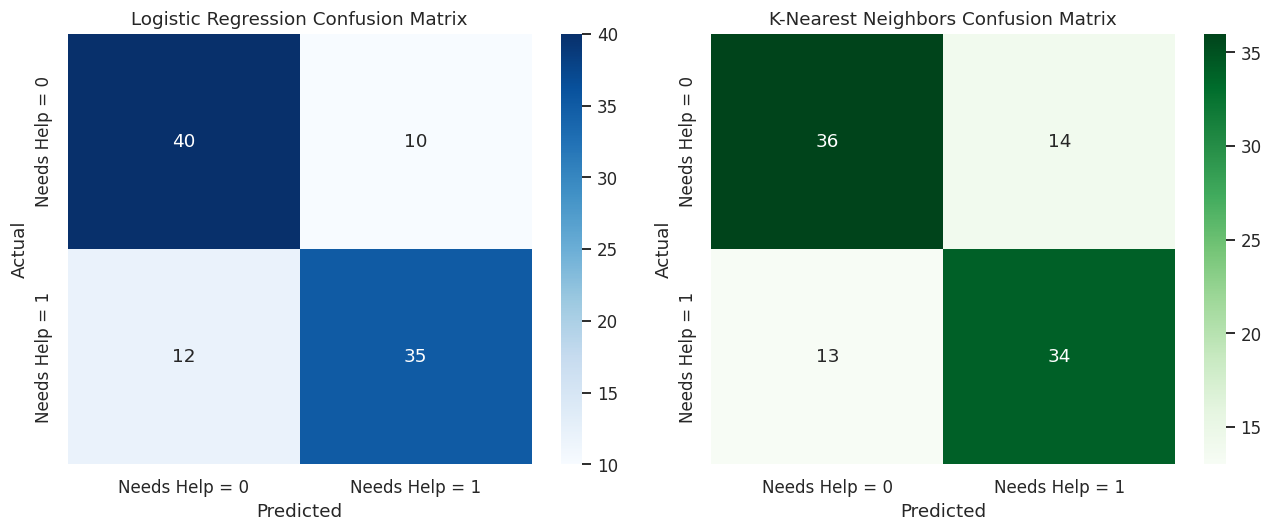

In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Predict using both models
y_pred_lr = best_lr.predict(X_test_scaled)
y_pred_knn = best_knn.predict(X_test_scaled)

# Compute metrics
metrics = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr)
    ],
    "K-Nearest Neighbors": [
        accuracy_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_knn)
    ]
}

metrics_df = pd.DataFrame(metrics)
display(metrics_df.round(4))

# Plot Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Logistic Regression Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred_lr)
sns.heatmap(cm_lr, annot=True, fmt="d", cmap="Blues", ax=axes[0],
            xticklabels=["Needs Help = 0", "Needs Help = 1"],
            yticklabels=["Needs Help = 0", "Needs Help = 1"])
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# KNN Confusion Matrix
cm_knn = confusion_matrix(y_test, y_pred_knn)
sns.heatmap(cm_knn, annot=True, fmt="d", cmap="Greens", ax=axes[1],
            xticklabels=["Needs Help = 0", "Needs Help = 1"],
            yticklabels=["Needs Help = 0", "Needs Help = 1"])
axes[1].set_title("K-Nearest Neighbors Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

### **8. Bonus Challenge (Optional): Comparing with another model & Hyperparameter Tuning**

To address the bonus challenge, we will train and tune a **Random Forest Classifier** to compare against our Logistic Regression and K-Nearest Neighbors models. Since Random Forests can capture complex non-linear relationships and interactions without assuming feature linearity, it serves as an excellent comparison model.

In [34]:
from sklearn.ensemble import RandomForestClassifier

# Define the hyperparameter grid for Random Forest
rf_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 5, 10, 15],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Perform Grid Search
grid_rf = GridSearchCV(RandomForestClassifier(random_state=42), rf_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid_rf.fit(X_train_scaled, y_train)

best_rf = grid_rf.best_estimator_

print("Best Random Forest parameters:", grid_rf.best_params_)
print(f"Best Random Forest CV Accuracy: {grid_rf.best_score_:.4f}")

# Evaluate on testing set
y_pred_rf = best_rf.predict(X_test_scaled)

# Compare all three models
comparison_metrics = {
    "Metric": ["Accuracy", "Precision", "Recall", "F1 Score"],
    "Logistic Regression": [
        accuracy_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_lr)
    ],
    "K-Nearest Neighbors": [
        accuracy_score(y_test, y_pred_knn),
        precision_score(y_test, y_pred_knn),
        recall_score(y_test, y_pred_knn),
        f1_score(y_test, y_pred_knn)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf)
    ]
}

comparison_df = pd.DataFrame(comparison_metrics)
display(comparison_df.round(4))

Best Random Forest parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
Best Random Forest CV Accuracy: 0.7682


,Metric,Logistic Regression,K-Nearest Neighbors,Random Forest
0,Accuracy,0.7732,0.7216,0.7320
1,Precision,0.7778,0.7083,0.7442
2,Recall,0.7447,0.7234,0.6809
3,F1 Score,0.7609,0.7158,0.7111
